# Ride-time prior for East Bay Paratransit

Model: $\log R = \log \text{shape}(d) + \log(\text{scale}) + \eta$, with the shape of ride time vs distance from NYC (dataset `w9xt-anps`), the level scaled so EBP's average trip (11.43 mi) has its reported average ride (48.9 min), and the spread $\eta$ from NYC's actual/scheduled ride-time buckets plus an assumed extra term (`S_EXTRA`).

**Check cell 3's printed label mapping before trusting the fits.**

### 1. Imports & constants

In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
from urllib.parse import urlencode

# East Bay Paratransit performance report, Jul '25–Apr '26 (EBPAC packet, July 7, 2026)
EBP_AVG_RIDE_MIN = 48.9        # average ride duration (minutes)
EBP_AVG_TRIP_MI = 11.43        # average trip length (miles)

S_EXTRA = 0.15                 # ASSUMPTION: extra log-spread because we predict from distance only,
                               # while NYC's ratio is relative to the scheduler's own plan
OVER_14_MI = 17.0              # ASSUMPTION: representative distance for the ">14 mi" band

BLUE, ORANGE, GRAY, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

### 2. Load NYC Access-A-Ride ride time (dataset w9xt-anps, 2024–present)

In [18]:
q = {"$select": "distance, peak_hour, percent_of_scheduled_ride_time_category as cat, "
                "within_max_ride_time as within_max, "
                "sum(total_trips) as n, sum(total_ride_time_min) as minutes",
     "$group": "distance, peak_hour, percent_of_scheduled_ride_time_category, within_max_ride_time",
     "$limit": 50000}
rt = pd.read_csv(f"https://data.ny.gov/resource/w9xt-anps.csv?{urlencode(q)}")
print(rt.shape)
print("distance labels:", sorted(rt["distance"].unique()))
print("ratio labels:   ", sorted(rt["cat"].unique()))
print("peak labels:    ", sorted(rt["peak_hour"].unique()))
print("within max:     ", sorted(rt["within_max"].astype(str).unique()))

(120, 6)
distance labels: ['0-3 miles', '12-14 miles', '3-6 miles', '6-9 miles', '9-12 miles', 'More than 14 miles']
ratio labels:    ['100-125%', '125-150%', '150-200%', '<=100%', 'Over 200%']
peak labels:     ['Off-Peak', 'Peak']
within max:      ['False', 'True']


### 3. Parse the category labels into numbers (check the printed mapping!)

In [19]:
def band_key(label, over_value):
    """Representative number for labels like '0-3', '<=100%', '100%-125%', '>200%', 'More than 14'."""
    s = str(label).lower()
    nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s)]
    if len(nums) >= 2:
        return np.mean(nums[:2])
    if any(t in s for t in ["<", "under", "at or below", "less"]):
        return nums[0] / 2
    if any(t in s for t in [">", "over", "more", "greater", "+"]):
        return over_value(nums[0])
    return nums[0]

dist_map = {l: band_key(l, lambda x: OVER_14_MI) for l in rt["distance"].unique()}
cat_map = {l: band_key(l, lambda x: x * 1.25) for l in rt["cat"].unique()}
rt["dist_mi"] = rt["distance"].map(dist_map)
rt["cat_key"] = rt["cat"].map(cat_map)
print("distance ->", dict(sorted(dist_map.items(), key=lambda kv: kv[1])))
print("ratio    ->", dict(sorted(cat_map.items(), key=lambda kv: kv[1])))

CATS = sorted(rt["cat"].unique(), key=cat_map.get)              # ordered ratio buckets
RATIO_EDGES = [1.0, 1.25, 1.5, 2.0]                             # boundaries between those buckets (actual/scheduled)
assert len(CATS) == len(RATIO_EDGES) + 1, CATS

distance -> {'0-3 miles': np.float64(1.5), '3-6 miles': np.float64(4.5), '6-9 miles': np.float64(7.5), '9-12 miles': np.float64(10.5), '12-14 miles': np.float64(13.0), 'More than 14 miles': 17.0}
ratio    -> {'<=100%': 50.0, '100-125%': np.float64(112.5), '125-150%': np.float64(137.5), '150-200%': np.float64(175.0), 'Over 200%': 250.0}


### 4. Explore: average ride by distance, share of ratio buckets, max-ride-time compliance

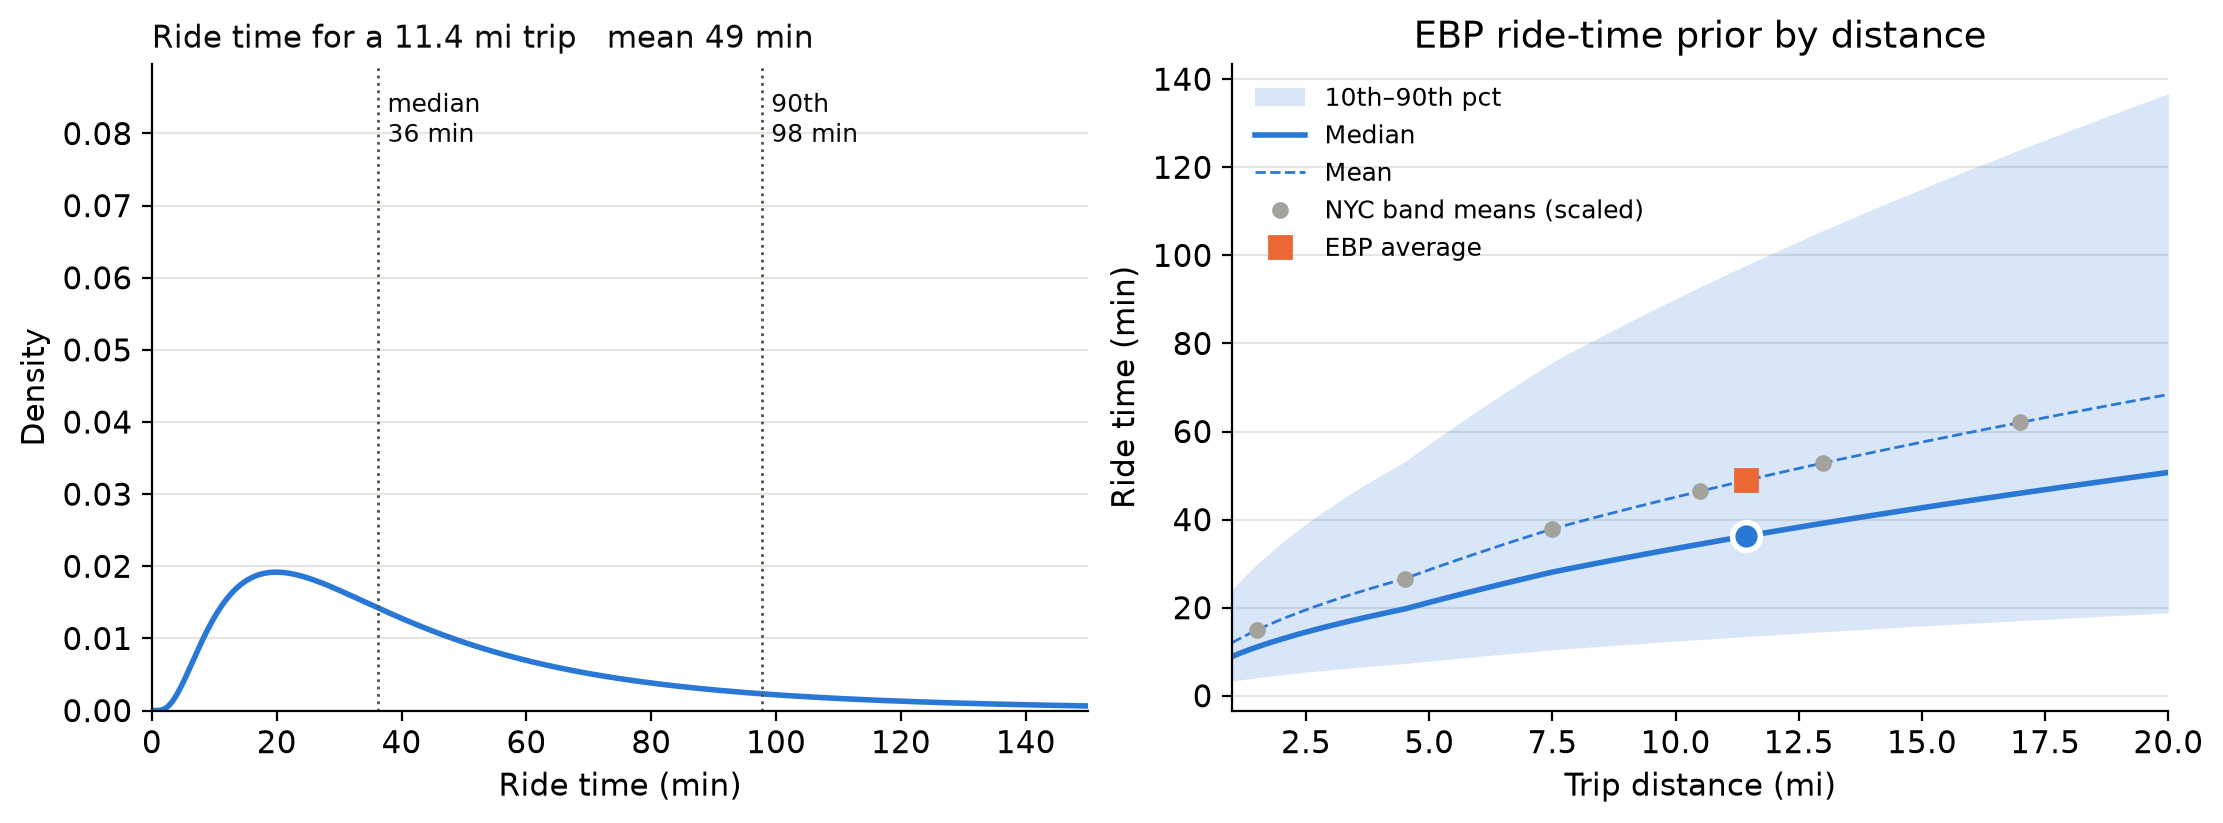

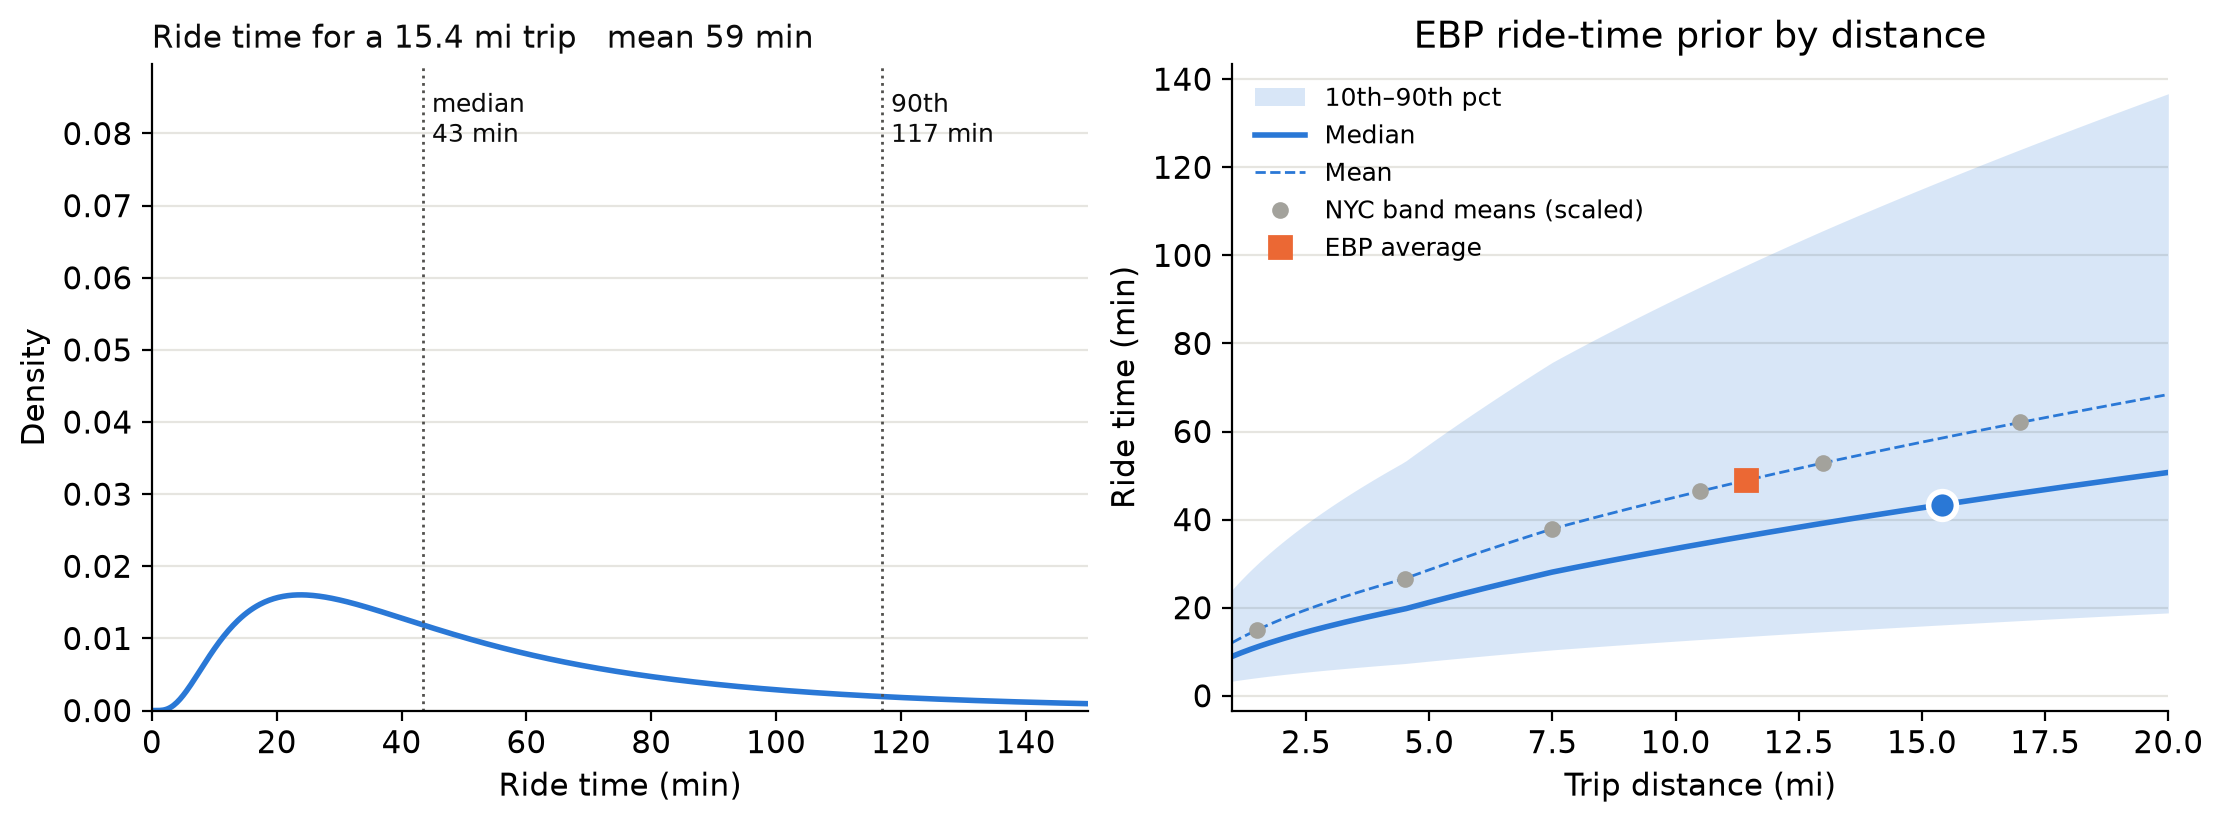

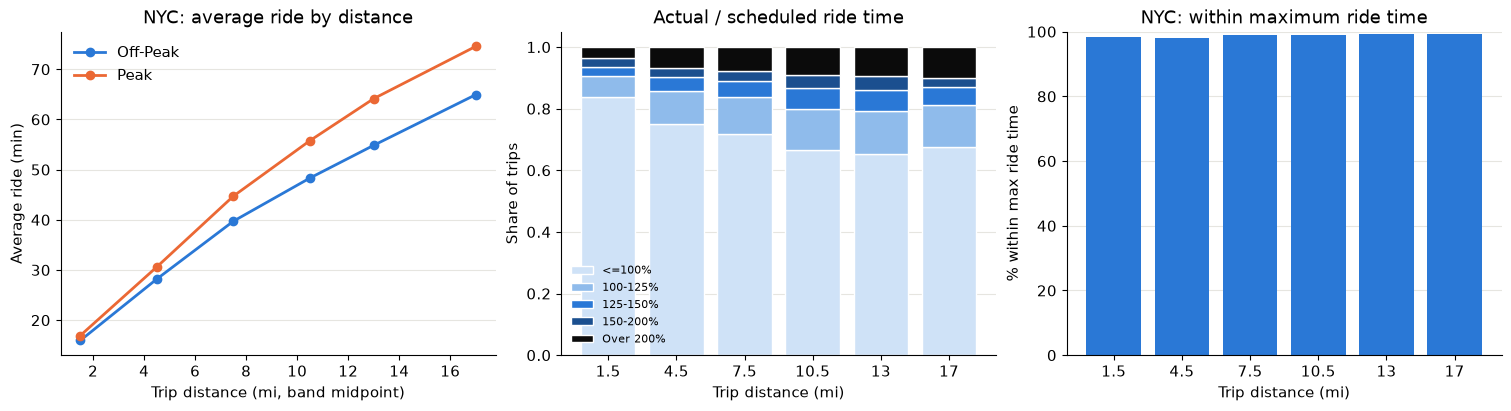

In [20]:
%matplotlib inline
by_band = (rt.groupby(["dist_mi", "peak_hour"])
             .apply(lambda g: pd.Series({"trips": g.n.sum(), "avg_ride": g.minutes.sum() / g.n.sum()}))
             .reset_index())
mix = (rt.groupby(["dist_mi", "cat"]).n.sum().unstack("cat")[CATS])
mix = mix.div(mix.sum(axis=1), axis=0)
within = (rt.assign(ok=rt["within_max"].astype(str).str.lower().isin(["yes", "true", "y", "1"]))
            .groupby("dist_mi").apply(lambda g: g.loc[g.ok, "n"].sum() / g.n.sum()))

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for (peak, g), col in zip(by_band.groupby("peak_hour"), [BLUE, ORANGE]):
    a1.plot(g.dist_mi, g.avg_ride, "o-", color=col, lw=2, label=str(peak))
a1.set(xlabel="Trip distance (mi, band midpoint)", ylabel="Average ride (min)",
       title="NYC: average ride by distance")
a1.legend(frameon=False)

bottom = np.zeros(len(mix))
shades = ["#cfe2f7", "#8fbbeb", "#2a78d6", "#1b4f8f", "#0b0b0b"]
for c, col in zip(CATS, shades):
    a2.bar(range(len(mix)), mix[c], bottom=bottom, color=col, edgecolor="white", lw=1, label=c)
    bottom += mix[c].to_numpy()
a2.set_xticks(range(len(mix)), [f"{d:g}" for d in mix.index])
a2.set(xlabel="Trip distance (mi)", ylabel="Share of trips", title="Actual / scheduled ride time")
a2.legend(frameon=False, fontsize=8, loc="lower left")

a3.bar(range(len(within)), 100 * within.to_numpy(), color=BLUE)
a3.set_xticks(range(len(within)), [f"{d:g}" for d in within.index])
a3.set(xlabel="Trip distance (mi)", ylabel="% within max ride time", ylim=(0, 100),
       title="NYC: within maximum ride time")
for ax in (a1, a2, a3):
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

### 5. Fit a lognormal to actual/scheduled per distance band and peak/off-peak

In [21]:
def fit_ratio(counts):
    """Interval-bucket lognormal fit; counts in CATS order. Returns (mu_rho, s_rho)."""
    def nll(t):
        F = stats.norm.cdf((np.log(RATIO_EDGES) - t[0]) / np.exp(t[1]))
        p = np.diff(np.concatenate([[0], F, [1]]))
        return -np.sum(counts * np.log(np.clip(p, 1e-300, None)))
    r = optimize.minimize(nll, [0.0, np.log(0.3)], method="Nelder-Mead",
                          options=dict(xatol=1e-9, fatol=1e-9))
    return r.x[0], np.exp(r.x[1])

rows = []
for (d, peak), g in rt.groupby(["dist_mi", "peak_hour"]):
    counts = g.groupby("cat").n.sum().reindex(CATS, fill_value=0).to_numpy(float)
    mu_r, s_r = fit_ratio(counts)
    F = stats.norm.cdf((np.log(RATIO_EDGES) - mu_r) / s_r)
    p_fit = np.diff(np.concatenate([[0], F, [1]]))
    rows.append(dict(dist_mi=d, peak=peak, trips=counts.sum(), mu_rho=mu_r, s_rho=s_r,
                     median_ratio=np.exp(mu_r),
                     worst_rel_err=np.max(np.abs(p_fit - counts / counts.sum()) /
                                          np.maximum(counts / counts.sum(), 1e-9))))
ratio_fit = pd.DataFrame(rows)
print(ratio_fit.round(3).to_string(index=False))

S_RHO = np.average(ratio_fit.s_rho, weights=ratio_fit.trips)      # pooled spread
print(f"\npooled s_rho = {S_RHO:.3f}")

 dist_mi     peak     trips  mu_rho  s_rho  median_ratio  worst_rel_err
     1.5 Off-Peak 4481606.0  -0.825  0.834         0.438          0.296
     1.5     Peak 1905056.0  -0.821  0.815         0.440          0.339
     4.5 Off-Peak 4044140.0  -0.535  0.791         0.586          0.875
     4.5     Peak 1853103.0  -0.519  0.733         0.595          0.868
     7.5 Off-Peak 2669357.0  -0.454  0.788         0.635          1.003
     7.5     Peak 1218016.0  -0.444  0.708         0.641          1.117
    10.5 Off-Peak 2051146.0  -0.315  0.732         0.730          0.785
    10.5     Peak  912625.0  -0.299  0.649         0.741          0.844
    13.0 Off-Peak 1031440.0  -0.295  0.730         0.745          0.853
    13.0     Peak  436931.0  -0.280  0.650         0.755          0.950
    17.0 Off-Peak 2161403.0  -0.023  0.646         0.977          2.701
    17.0     Peak  845189.0  -0.338  0.689         0.713          1.486

pooled s_rho = 0.759


### 6. Ride prior for the East Bay: NYC shape vs distance, scaled to EBP's 48.9 min at 11.43 mi

In [22]:
# NYC average ride vs distance (all hours), interpolated in log-log space
shape = (rt.groupby("dist_mi").apply(lambda g: g.minutes.sum() / g.n.sum())).sort_index()
_logd, _logr = np.log(shape.index.to_numpy()), np.log(shape.to_numpy())

def nyc_avg_ride(d_mi):
    """Log-log interpolation between bands; straight-line extrapolation beyond the outermost ones."""
    x = np.log(np.asarray(d_mi, float))
    y = np.interp(x, _logd, _logr)
    lo_slope = (_logr[1] - _logr[0]) / (_logd[1] - _logd[0])
    hi_slope = (_logr[-1] - _logr[-2]) / (_logd[-1] - _logd[-2])
    y = np.where(x < _logd[0], _logr[0] + lo_slope * (x - _logd[0]), y)
    y = np.where(x > _logd[-1], _logr[-1] + hi_slope * (x - _logd[-1]), y)
    return np.exp(y)

S_RIDE = np.sqrt(S_RHO**2 + S_EXTRA**2)                    # total log-spread of our prediction
SCALE = EBP_AVG_RIDE_MIN / nyc_avg_ride(EBP_AVG_TRIP_MI)   # level from EBP

def ride_prior(d_mi):
    """Lognormal ride-time prior (minutes) for an EBP trip of d_mi miles.
    The calibrated quantity is the MEAN ride, so median = mean * exp(-s^2/2)."""
    mean = SCALE * nyc_avg_ride(d_mi)
    return stats.lognorm(S_RIDE, scale=mean * np.exp(-S_RIDE**2 / 2))

print(f"S_RIDE = {S_RIDE:.3f}, scale NYC->EBP = {SCALE:.2f}")
for d in (2, 5, 8, 11.43, 15):
    r = ride_prior(d)
    print(f"{d:>5} mi: mean {r.mean():5.1f}  median {r.median():5.1f}  90th {r.ppf(0.9):5.1f} min")

S_RIDE = 0.774, scale NYC->EBP = 0.92
    2 mi: mean  17.3  median  12.9  90th  34.7 min
    5 mi: mean  28.6  median  21.2  90th  57.1 min
    8 mi: mean  39.4  median  29.2  90th  78.7 min
11.43 mi: mean  48.9  median  36.2  90th  97.7 min
   15 mi: mean  57.6  median  42.7  90th 115.1 min


### 7. Interactive: ride distribution by distance (smooth slider; needs ipympl)

In [23]:
%matplotlib widget
import ipywidgets as widgets

xr = np.linspace(0, 150, 600)
d_grid = np.linspace(1, 20, 200)

plt.ioff()
fig, (b1, b2) = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
fig.canvas.header_visible = False

pdf_line, = b1.plot(xr, np.zeros_like(xr), color=BLUE, lw=2)
q_lines = [b1.axvline(0, color=MUTED, lw=1, ls=":") for _ in range(2)]
q_texts = [b1.text(0, 0, "", color=INK, fontsize=9) for _ in range(2)]
ymax_r = max(ride_prior(d).pdf(xr).max() for d in d_grid[::20]) * 1.15
b1.set(xlim=(0, 150), ylim=(0, ymax_r), xlabel="Ride time (min)", ylabel="Density")
title_r = b1.set_title("", loc="left", color=INK, fontsize=11)

med = np.array([ride_prior(d).median() for d in d_grid])
p10 = np.array([ride_prior(d).ppf(0.1) for d in d_grid])
p90 = np.array([ride_prior(d).ppf(0.9) for d in d_grid])
b2.fill_between(d_grid, p10, p90, color=BLUE, alpha=0.18, lw=0, label="10th–90th pct")
b2.plot(d_grid, med, color=BLUE, lw=2, label="Median")
b2.plot(d_grid, [ride_prior(d).mean() for d in d_grid], color=BLUE, lw=1, ls="--", label="Mean")
b2.plot(shape.index, SCALE * shape.to_numpy(), "o", color=GRAY, ms=5, label="NYC band means (scaled)")
b2.plot([EBP_AVG_TRIP_MI], [EBP_AVG_RIDE_MIN], "s", color=ORANGE, ms=8, label="EBP average")
dot_r, = b2.plot([], [], "o", ms=10, color=BLUE, mec="white", mew=2)
b2.set(xlim=(1, 20), xlabel="Trip distance (mi)", ylabel="Ride time (min)",
       title="EBP ride-time prior by distance")
b2.legend(frameon=False, loc="upper left", fontsize=9)
for ax in (b1, b2):
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)

def update(d):
    r = ride_prior(d)
    pdf_line.set_ydata(r.pdf(xr))
    for line, txt, (q_, lab) in zip(q_lines, q_texts, [(0.5, "median"), (0.9, "90th")]):
        v = r.ppf(q_)
        line.set_xdata([v, v])
        txt.set_position((v + 1.5, ymax_r * 0.88))
        txt.set_text(f"{lab}\n{v:.0f} min")
    title_r.set_text(f"Ride time for a {d:.1f} mi trip   mean {r.mean():.0f} min")
    dot_r.set_data([d], [r.median()])
    fig.canvas.draw_idle()

slider = widgets.FloatSlider(value=EBP_AVG_TRIP_MI, min=1.0, max=20.0, step=0.1,
                             description="Distance", continuous_update=True,
                             layout=widgets.Layout(width="60%"))
slider.observe(lambda ch: update(ch["new"]), names="value")
update(slider.value)
display(widgets.VBox([slider, fig.canvas]))

### 8. Optional: replace distance with Google drive time (traffic-aware, for a given departure)

In [24]:
# Needs GOOGLE_MAPS_KEY in the environment and the Routes API enabled.
import os, json, urllib.request

def google_drive_minutes(origin, destination, departure_iso):
    """origin/destination: (lat, lng). departure_iso: e.g. '2026-10-29T13:00:00-07:00'."""
    body = {"origin": {"location": {"latLng": {"latitude": origin[0], "longitude": origin[1]}}},
            "destination": {"location": {"latLng": {"latitude": destination[0], "longitude": destination[1]}}},
            "travelMode": "DRIVE", "routingPreference": "TRAFFIC_AWARE_OPTIMAL",
            "departureTime": departure_iso}
    req = urllib.request.Request(
        "https://routes.googleapis.com/directions/v2:computeRoutes", data=json.dumps(body).encode(),
        headers={"Content-Type": "application/json", "X-Goog-Api-Key": os.environ["GOOGLE_MAPS_KEY"],
                 "X-Goog-FieldMask": "routes.duration,routes.distanceMeters"})
    route = json.load(urllib.request.urlopen(req))["routes"][0]
    return float(route["duration"].rstrip("s")) / 60, route["distanceMeters"] / 1609.34

# Example (uncomment once the key is set): Fruitvale BART -> Highland Hospital, Thursday 1pm
# mins, miles = google_drive_minutes((37.7748, -122.2241), (37.7990, -122.2312), "2026-10-29T13:00:00-07:00")
# print(f"drive {mins:.1f} min, {miles:.1f} mi -> ride prior median {ride_prior(miles).median():.0f} min")